## Modular forms

These run on Sagebrush's Rust engines, compiled to WebAssembly. The Hecke polynomial of $T_p$ on the modular symbols for $\Gamma_0(N)$ is exact and *proven*, and the Sato–Tate moments of $a_p^2/p$ approach the Catalan numbers $1, 2, 5, 14, \dots$

In [ ]:
# Modular symbols, computed by Sagebrush's Rust engine in your browser:
# exact Hecke polynomials, proven by a coefficient bound
M = ModularSymbols(389, 2, sign=1)
M, M.hecke_polynomial(2)

(Modular Symbols space of dimension 33 for Gamma_0(389) of weight 2 with sign 1 over Rational Field, x^33 - x^32 - 52*x^31 + 46*x^30 + 1219*x^29 - 939*x^28 - 17044*x^27 + 11220*x^26 + 158471*x^25 - 87155*x^24 - 1034158*x^23 + 462016*x^22 + 4872986*x^21 - 1705222*x^20 - 16801171*x^19 + 4376327*x^18 + 42496356*x^17 - 7598744*x^16 - 78351538*x^15 + 8196260*x^14 + 103678217*x^13 - 3810733*x^12 - 95894495*x^11 - 2530565*x^10 + 59468374*x^9 + 5119626*x^8 - 23144358*x^7 - 3273560*x^6 + 5051976*x^5 + 943872*x^4 - 502432*x^3 - 103920*x^2 + 16528*x + 3552)


In [ ]:
# Spaces with a character (nebentypus)
eps = DirichletGroup(13).gen()^2
M = ModularSymbols(eps, 2, sign=1)
print(eps)
M, M.hecke_polynomial(2)

Dirichlet character modulo 13 of conductor 13 mapping 2 |--> zeta12^2
(Modular Symbols space of dimension 3 and level 13, weight 2, character [zeta6], sign 1, over Cyclotomic Field of order 6 and degree 2, x^3 + (-2*zeta6 - 2)*x^2 - 2*zeta6*x + 14*zeta6 - 7)


In [ ]:
# Dimensions of spaces of cusp forms and newforms
[(N, CuspForms(N, 2).dimension(), Gamma0(N).dimension_new_cusp_forms(2)) for N in range(11, 31)]

[(11, 1, 1), (12, 0, 0), (13, 0, 0), (14, 1, 1), (15, 1, 1), (16, 0, 0), (17, 1, 1), (18, 0, 0), (19, 1, 1), (20, 1, 1), (21, 1, 1), (22, 2, 0), (23, 2, 2), (24, 1, 1), (25, 0, 0), (26, 2, 2), (27, 1, 1), (28, 2, 0), (29, 2, 2), (30, 3, 1)]


In [ ]:
# Elliptic curves: Cremona's curves of conductor < 1000 by label
E = EllipticCurve('389a1')
E, E.rank(), E.torsion_order(), E.aplist(50), E.anlist(12)

(Elliptic Curve defined by y^2 + y = x^3 + x^2 - 2*x over Rational Field, 2, 1, [-2, -2, -3, -5, -4, -3, -6, 5, -4, -6, 4, -8, -3, 12, -2], [0, 1, -2, -2, 2, -3, 4, -5, 0, 1, 6, -4, -4])


### The Birch and Swinnerton-Dyer formula

For a curve of analytic rank $0$, $$\frac{L(E,1)}{\Omega_E} = \frac{\#\text{Ш}(E/\mathbb{Q}) \prod_p c_p}{\#E(\mathbb{Q})_{\rm tors}^2}.$$ Sagebrush computes every ingredient: the conductor and the Tamagawa numbers $c_p$ by Tate's algorithm, the torsion by Nagell–Lutz, the real period $\Omega_E$ by the arithmetic-geometric mean, the root number and $L(E,1)$ from the rapidly converging series, and then $L(E,1)/\Omega_E$ exactly as a rational number. On all 64,687 curves of conductor below $10^4$ the results agree with Cremona's tables. The curve below, of conductor $681$, has a Tate–Shafarevich group of order $9$.

In [ ]:
E = EllipticCurve([1, 1, 0, -1154, -15345])
E.conductor(), E.tamagawa_numbers(), E.torsion_order(), E.period_lattice().omega(), E.lseries().L_ratio(), E.sha().an()

(681, [2, 2], 4, 0.819917869389698, 9/4, 9)


In [ ]:
# Local data at the bad primes: Kodaira symbols and Tamagawa numbers (Tate's algorithm)
E = EllipticCurve([0, 0, 0, -192, 512])
E.minimal_model(), E.conductor(), [(p, E.kodaira_symbol(p), E.tamagawa_number(p)) for p in E.bad_primes()]

(Elliptic Curve defined by y^2 = x^3 - 12*x + 8 over Rational Field, 5184, [(2, I0*, 1), (3, II, 1)])


In [ ]:
# Rank 1: a generator (point search), its canonical height (for rank 1, the regulator), and Sha from L'(E,1)
E = EllipticCurve([0, 0, 0, -36, 0])   # y^2 = x^3 - 36x: 6 is a congruent number
P = E.gens()[0]
P, P.height(), E.sha().an()

((-3 : -9 : 1), 0.888625874839619, 1)


In [ ]:
# Descent via 2-isogeny: rank bounds from Selmer groups (local solubility of quartics);
# 41 is a congruent number of rank 2, and 336d3 has rank 0 but Sha of order 4
[EllipticCurve([0, 0, 0, -41^2, 0]).two_descent_by_two_isogeny(), EllipticCurve([0, 1, 0, -21504, -1220940]).two_descent_by_two_isogeny()]

[(2, 2), (0, 2)]


In [ ]:
# General 2-descent (no rational 2-torsion): integral binary quartics with invariants c4, 2 c6,
# found by a reduction-theory search in Rust; [0,0,1,-7,6] is 5077a1 of rank 3, 571a1 has Sha[2] = (Z/2)^2
for lab in ['389a1', [0, 0, 1, -7, 6], '571a1']:
    E = EllipticCurve(lab)
    print(lab, E.two_descent(), E.selmer_rank(), E._general_two_descent()['rank_bounds'])

389a1 True 2 (2, 2)


[0, 0, 1, -7, 6] True 3 (3, 3)


571a1 False 2 (0, 2)


In [ ]:
# Root numbers and analytic ranks (numerical beyond 1: proof=True certifies only 0 and 1)
[(lab, EllipticCurve(lab).root_number(), EllipticCurve(lab).analytic_rank(leading_coefficient=True)) for lab in ['11a1', '37a1', '389a1', [0, 0, 1, -7, 6]]]

[('11a1', 1, (0, 0.253841860855911)), ('37a1', -1, (1, 0.305999773834052)), ('389a1', 1, (2, 1.51863300057685)), ([0, 0, 1, -7, 6], -1, (3, 10.3910994007158))]


In [ ]:
# An open problem: 234446a1 is the rank 4 curve of smallest conductor. Four points on it are
# independent (their height pairing matrix is nonsingular), so its rank is at least 4, and here
# its 2-descent bounds the rank by 4 assuming GRH (class groups in the 2-Selmer computation):
# rank_bounds() is (4, 4). Numerically L(E,s) vanishes to order 4 at s = 1 (proof=False is the
# default), but proving that any elliptic curve has analytic rank >= 4 is a central open problem
E = EllipticCurve([1, -1, 0, -79, 289])
P = [E(6, -5), E(4, -7), E(5, -3), E(8, -15)]
print(E.height_pairing_matrix(P).det() != 0, E.rank_bounds(), E.analytic_rank())
try:
    E.analytic_rank(proof=True)
except NotImplementedError as e:
    print(e)

True (4, 4) 4


analytic rank 4 is only numerical: L^(k)(E,1) for k < 4 are merely small (use proof=False)


In [ ]:
# Documentation: obj? shows the signature and docstring (with tested examples), obj?? the source;
# help(obj) works too, and Tab after a dot lists the methods
E = EllipticCurve('389a1')
E.analytic_rank?

Signature: E.analytic_rank(proof=False, leading_coefficient=False)
Docstring:
The order of vanishing of L(E,s) at s = 1: the first r of the parity
of the root number with L^(r)(E,1) numerically nonzero (as in Sage).

INPUT:

- ``proof`` -- (default: False) if True, return only ranks that are
  proved: 0 and 1 (nothing has to vanish then: root number -1 forces
  L(E,1) = 0).  The root number and L(E,1) or L'(E,1) are enclosed
  on balls (engine/ap/src/lcert.rs: every exponential and E_1
  enclosed, the tails bounded with |a_n| <= 2n), so a nonzero
  enclosure proves rank 0 (Kolyvagin) or 1 (Gross-Zagier, Kolyvagin)
  with no floating-point assumption.  For r >= 2 it raises NotImplementedError, since
  showing that L^(k)(E,1) is exactly 0 for k < r is a separate
  problem: possible for r = 2, 3 (modular symbols, Gross-Zagier),
  not implemented here, and open for every curve when r >= 4.
- ``leading_coefficient`` -- (default: False) if True, return
  (r, L^(r)(E,1)), as Sage does.

ALGOR

In [ ]:
# Sato-Tate: the moments of a_p^2/p over the primes below 10^6 tend to the Catalan numbers 1, 2, 5, 14
EllipticCurve('11a1').sato_tate_moments(10^6)

(78497, [0.9982233469711914, 1.9924653529315548, 4.968458634908204, 13.870540054549444])


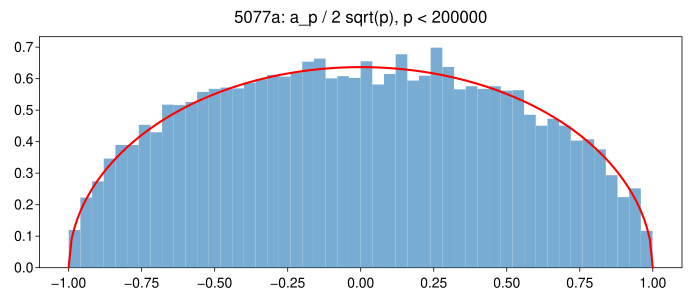

In [ ]:
# The Sato-Tate distribution of a_p / 2 sqrt(p) against the semicircle (in floating point)
import math
import matplotlib.pyplot as plt
E = EllipticCurve([0, 0, 1, -7, 6])
ps = prime_range(3, 2*10^5)
t = [float(a) / (2 * math.sqrt(p)) for p, a in zip(ps, E.aplist(2*10^5)[1:])]
plt.figure(figsize=(7, 3))
plt.hist(t, bins=50, density=True, alpha=0.6)
xs = [k / 100 for k in range(-100, 101)]
plt.plot(xs, [2 / math.pi * math.sqrt(1 - u*u) for u in xs], 'r')
plt.title('5077a: a_p / 2 sqrt(p), p < 200000')

In [ ]:
# Newforms (when every coefficient is rational, exactly as Sage prints them)
Newforms(57, names='a')

[q - 2*q^2 - q^3 + 2*q^4 - 3*q^5 + O(q^6), q - 2*q^2 + q^3 + 2*q^4 + q^5 + O(q^6), q + q^2 + q^3 - q^4 - 2*q^5 + O(q^6)]


In [ ]:
# Every Galois orbit of newforms, with its LMFDB label, dimension and trace form
for f in newform_orbits(389):
    print(f)
newform_orbits(389)[-1].charpoly()

389.2.a.a (dimension 1): q - 2*q^2 - 2*q^3 + 2*q^4 - 3*q^5 + O(q^6)
389.2.a.b (dimension 2): 2*q - 4*q^3 - 2*q^5 + O(q^6)
389.2.a.c (dimension 3): 3*q + 2*q^4 - 5*q^5 + O(q^6)
389.2.a.d (dimension 6): 6*q - 3*q^2 - 5*q^3 + q^4 + 3*q^5 + O(q^6)
389.2.a.e (dimension 20): 20*q + 3*q^2 + 11*q^3 + 27*q^4 + q^5 + O(q^6)
x^20 - 36*x^19 + 238*x^18 + 5938*x^17 - 89638*x^16 - 98459*x^15 + 8381042*x^14 - 31945454*x^13 - 300466488*x^12 + 2266802048*x^11 + 2323820867*x^10 - 58089218087*x^9 + 92671844985*x^8 + 561570921194*x^7 - 1869681316392*x^6 - 683117287589*x^5 + 8599815908447*x^4 - 6905582251608*x^3 - 6096196967352*x^2 + 5699822108448*x + 21372607552


In [ ]:
# The engines directly: the same API as the native CPython package
from sagebrush import modsym
modsym.rational_newforms(37, 50)

[[(2, -2), (3, -3), (5, -2), (7, -1), (11, -5), (13, -2), (17, 0), (19, 0), (23, 2), (29, 6), (31, -4), (41, -9), (43, 2), (47, -9)], [(2, 0), (3, 1), (5, 0), (7, -1), (11, 3), (13, -4), (17, 6), (19, 2), (23, 6), (29, -6), (31, -4), (41, -9), (43, 8), (47, 3)]]
